In [1]:
Problem 1 – Linear SVM from Scratch

In [4]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

np.random.seed(42)

In [5]:
# Generate the dataset
X, y = make_blobs(
    n_samples=300,
    centers=2,
    n_features=2,
    cluster_std=1.5,
    random_state=42
)

# Convert labels from {0, 1} to {-1, +1}
y = np.where(y == 0, -1, 1)

print("Dataset shape:", X.shape)
print("Labels:", np.unique(y))

Dataset shape: (300, 2)
Labels: [-1  1]


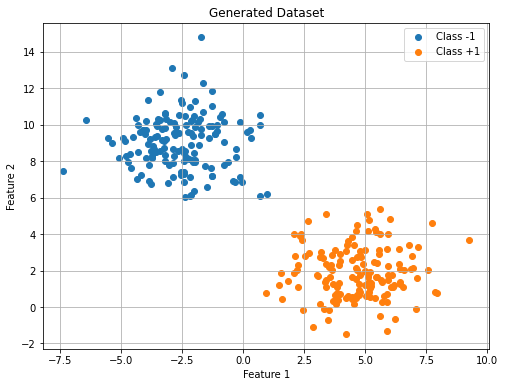

In [6]:
# Visualize the dataset:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[y == -1, 0],
    X[y == -1, 1],
    label="Class -1"
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Class +1"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Generated Dataset")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 210
Testing samples: 90


In [8]:
# Standardize the features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training feature means:", X_train.mean(axis=0))
print("Training feature standard deviations:", X_train.std(axis=0))

Training feature means: [-1.48029737e-16 -9.31001308e-16]
Training feature standard deviations: [1. 1.]


In [9]:
# Implement SVM from scratch
def decision_function(X, w, b):
    return np.dot(X, w) + b

In [10]:
# Implement predictions:
def predict(X, w, b):
    scores = decision_function(X, w, b)
    return np.where(scores >= 0, 1, -1)

In [11]:
# Implement hinge loss:
def hinge_loss(X, y, w, b):
    scores = decision_function(X, w, b)

    losses = np.maximum(
        0,
        1 - y * scores
    )

    return np.mean(losses)

In [12]:
# Implement the complete objective:
def svm_objective(X, y, w, b, lambda_value):
    regularization = (lambda_value / 2) * np.dot(w, w)

    loss = hinge_loss(X, y, w, b)

    return regularization + loss

In [13]:
# Implement batch subgradient descent
def train_svm(X, y, learning_rate, lambda_value, iterations=2000):

    n_samples, n_features = X.shape

    w = np.zeros(n_features)
    b = 0.0

    cost_history = []

    for iteration in range(iterations):

        scores = decision_function(X, w, b)

        margins = y * scores

        # Only observations with margin < 1 contribute
        active = margins < 1

        # Gradient calculations
        dw = lambda_value * w - np.mean(
            (active * y)[:, np.newaxis] * X,
            axis=0
        )

        db = -np.mean(active * y)

        # Update parameters
        w -= learning_rate * dw
        b -= learning_rate * db

        # Calculate objective
        cost = svm_objective(
            X, y, w, b, lambda_value
        )

        cost_history.append(cost)

    return w, b, cost_history

In [14]:
# Train using three learning rates
lambda_value = 0.01
learning_rates = [0.001, 0.01, 0.05]

models = {}

for lr in learning_rates:

    w, b, history = train_svm(
        X_train,
        y_train,
        learning_rate=lr,
        lambda_value=lambda_value,
        iterations=2000
    )

    models[lr] = {
        "w": w,
        "b": b,
        "history": history
    }

    print(f"\nLearning Rate: {lr}")
    print("Weights:", w)
    print("Bias:", b)
    print("Final Objective:", history[-1])


Learning Rate: 0.001
Weights: [ 0.7386803  -0.74291476]
Bias: 0.013038095238095092
Final Objective: 0.04563874646547267

Learning Rate: 0.01
Weights: [ 1.05418939 -1.04434014]
Bias: -0.012476190476190753
Final Objective: 0.02313905007455084

Learning Rate: 0.05
Weights: [ 1.16543193 -1.1452911 ]
Bias: -0.008095238095238079
Final Objective: 0.02280353516255774


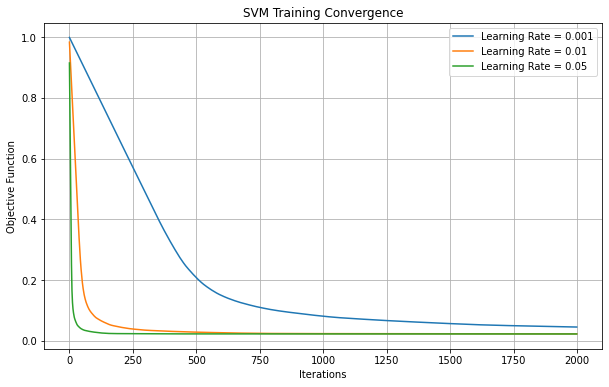

In [15]:
# Plot objective across iterations
plt.figure(figsize=(10, 6))

for lr in learning_rates:

    plt.plot(
        models[lr]["history"],
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Iterations")
plt.ylabel("Objective Function")
plt.title("SVM Training Convergence")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
# Plot decision boundary and margins
def plot_svm_boundary(X, y, w, b, title):

    plt.figure(figsize=(9, 7))

    plt.scatter(
        X[y == -1, 0],
        X[y == -1, 1],
        label="Class -1"
    )

    plt.scatter(
        X[y == 1, 0],
        X[y == 1, 1],
        label="Class +1"
    )

    # Observations with signed functional margin <= 1
    margins = y * decision_function(X, w, b)

    margin_points = margins <= 1 + 1e-8

    plt.scatter(
        X[margin_points, 0],
        X[margin_points, 1],
        facecolors="none",
        edgecolors="black",
        s=100,
        label="Margin or inside-margin observations"
    )

    x_values = np.linspace(
        X[:, 0].min() - 1,
        X[:, 0].max() + 1,
        300
    )

    for level, label in [
        (0, "Decision Boundary"),
        (1, "Positive Margin"),
        (-1, "Negative Margin")
    ]:

        if abs(w[1]) > 1e-10:

            y_values = (
                level - w[0] * x_values - b
            ) / w[1]

            plt.plot(
                x_values,
                y_values,
                linestyle="--" if level != 0 else "-",
                label=label
            )

        else:
            x_position = (level - b) / w[0]
            plt.axvline(
                x_position,
                linestyle="--" if level != 0 else "-",
                label=label
            )

    plt.xlabel("Standardized Feature 1")
    plt.ylabel("Standardized Feature 2")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

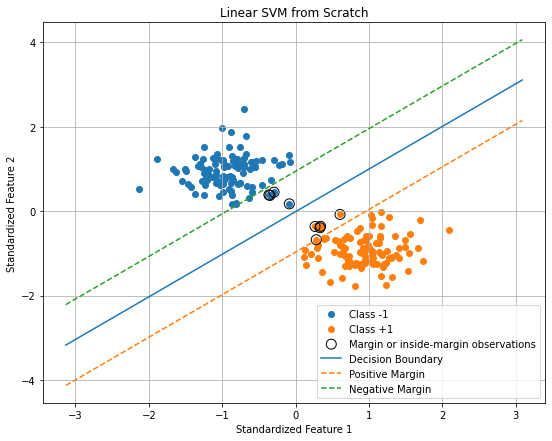

In [17]:
# Plot the model trained with learning rate 0.01:
best_lr = 0.01

w = models[best_lr]["w"]
b = models[best_lr]["b"]

plot_svm_boundary(
    X_train,
    y_train,
    w,
    b,
    "Linear SVM from Scratch"
)

In [18]:
# Identify observations inside and on the margin
margins = y_train * decision_function(
    X_train, w, b
)

inside_margin = margins < 1 - 1e-8

on_margin = np.isclose(
    margins,
    1,
    atol=1e-8
)

outside_margin = margins > 1 + 1e-8

print("Inside margin:", np.sum(inside_margin))
print("Exactly on margin:", np.sum(on_margin))
print("Outside margin:", np.sum(outside_margin))

print(
    "Misclassified observations:",
    np.sum(margins < 0)
)

Inside margin: 9
Exactly on margin: 0
Outside margin: 201
Misclassified observations: 0


In [19]:
# Evaluate the scratch SVM
y_pred = predict(X_test, w, b)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label=1))
print("Recall:", recall_score(y_test, y_pred, pos_label=1))
print("F1 Score:", f1_score(y_test, y_pred, pos_label=1))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Confusion Matrix:
[[45  0]
 [ 0 45]]

Classification Report:
              precision    recall  f1-score   support

          -1       1.00      1.00      1.00        45
           1       1.00      1.00      1.00        45

    accuracy                           1.00        90
   macro avg       1.00      1.00      1.00        90
weighted avg       1.00      1.00      1.00        90



In [20]:
# Compare with scikit-learn SVC
n = len(X_train)

C_value = 1 / (n * lambda_value)

print("Training samples:", n)
print("Lambda:", lambda_value)
print("Calculated C:", C_value)

Training samples: 210
Lambda: 0.01
Calculated C: 0.47619047619047616


In [21]:
# Train the scikit-learn model:
svc_model = SVC(
    kernel="linear",
    C=C_value
)

svc_model.fit(X_train, y_train)

svc_predictions = svc_model.predict(X_test)

print("SVC Accuracy:", accuracy_score(y_test, svc_predictions))
print("SVC Precision:", precision_score(y_test, svc_predictions, pos_label=1))
print("SVC Recall:", recall_score(y_test, svc_predictions, pos_label=1))
print("SVC F1 Score:", f1_score(y_test, svc_predictions, pos_label=1))

print("Support Vectors:", len(svc_model.support_vectors_))

SVC Accuracy: 1.0
SVC Precision: 1.0
SVC Recall: 1.0
SVC F1 Score: 1.0
Support Vectors: 8


In [22]:
# Compare the two models:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],

    "Scratch SVM": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label=1),
        recall_score(y_test, y_pred, pos_label=1),
        f1_score(y_test, y_pred, pos_label=1)
    ],

    "Scikit-learn SVM": [
        accuracy_score(y_test, svc_predictions),
        precision_score(y_test, svc_predictions, pos_label=1),
        recall_score(y_test, svc_predictions, pos_label=1),
        f1_score(y_test, svc_predictions, pos_label=1)
    ]
})

comparison

,Metric,Scratch SVM,Scikit-learn SVM
0,Accuracy,1.0,1.0
1,Precision,1.0,1.0
2,Recall,1.0,1.0
3,F1 Score,1.0,1.0


In [23]:
# Compare learned parameters:
print("Scratch weights:", w)
print("Scratch bias:", b)

print("SVC weights:", svc_model.coef_[0])
print("SVC bias:", svc_model.intercept_[0])

Scratch weights: [ 1.05418939 -1.04434014]
Scratch bias: -0.012476190476190753
SVC weights: [ 1.25442878 -1.2243006 ]
SVC bias: 0.014152133039065845


In [ ]:
Problem 2 – Effect of C on SVM

In [24]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, f1_score

In [25]:
# Generate the dataset
X, y = make_classification(
    n_samples=500,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.0,
    flip_y=0.08,
    random_state=42
)

print("Dataset shape:", X.shape)
print("Classes:", np.unique(y))

Dataset shape: (500, 2)
Classes: [0 1]


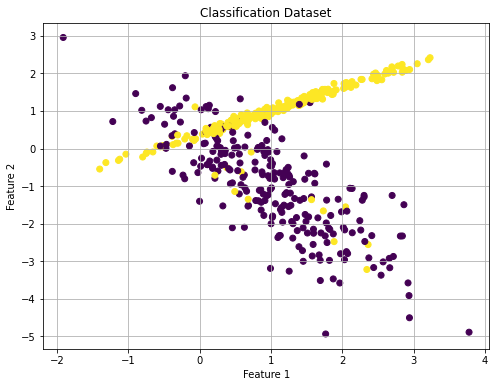

In [26]:
# Visualize:
plt.figure(figsize=(8, 6))

plt.scatter(X[:, 0], X[:, 1], c=y)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Classification Dataset")
plt.grid(True)
plt.show()

In [27]:
# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

Training samples: 350
Validation samples: 150


In [28]:
# Train SVM with different C values
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

results = []

models = {}

for C in C_values:

    model = SVC(
        kernel="linear",
        C=C
    )

    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    val_predictions = model.predict(X_val)

    train_accuracy = accuracy_score(y_train, train_predictions)
    val_accuracy = accuracy_score(y_val, val_predictions)

    train_f1 = f1_score(y_train, train_predictions)
    val_f1 = f1_score(y_val, val_predictions)

    results.append({
        "C": C,
        "Train Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Train F1": train_f1,
        "Validation F1": val_f1,
        "Support Vectors": len(model.support_vectors_)
    })

    models[C] = model

results_df = pd.DataFrame(results)

results_df

,C,Train Accuracy,Validation Accuracy,Train F1,Validation F1,Support Vectors
0,0.001,0.511429,0.513333,0.674286,0.675556,346
1,0.010,0.817143,0.806667,0.837563,0.836158,259
2,0.100,0.860000,0.813333,0.863510,0.833333,170
3,1.000,0.860000,0.813333,0.863510,0.833333,145
4,10.000,0.860000,0.813333,0.863510,0.833333,143
5,100.000,0.860000,0.813333,0.863510,0.833333,143


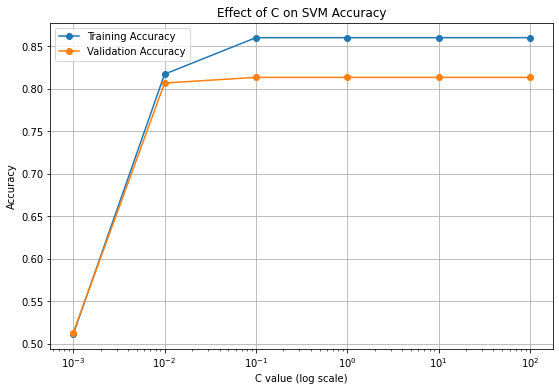

In [29]:
# Visualize the impact of C
plt.figure(figsize=(9, 6))

plt.plot(
    results_df["C"],
    results_df["Train Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    results_df["C"],
    results_df["Validation Accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xscale("log")
plt.xlabel("C value (log scale)")
plt.ylabel("Accuracy")
plt.title("Effect of C on SVM Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
# Plot decision boundaries
def plot_boundary(model, X, y, title):

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    Z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 5))

    plt.contourf(xx, yy, Z, alpha=0.2)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors="black", s=25)

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)
    plt.grid(True)
    plt.show()

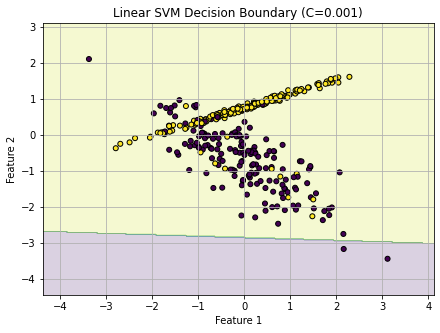

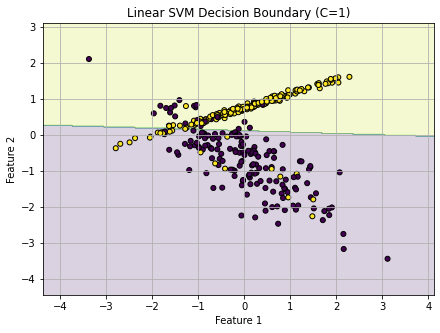

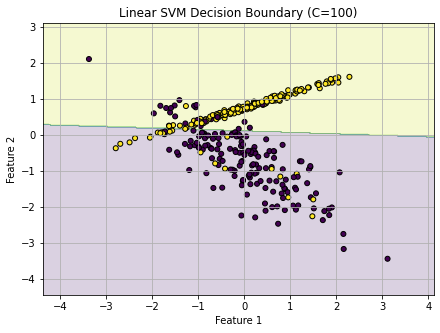

In [31]:
# Plot models for three representative values:
for C in [0.001, 1, 100]:

    plot_boundary(
        models[C],
        X_train,
        y_train,
        f"Linear SVM Decision Boundary (C={C})"
    )

In [32]:
# Select the best C
best_row = results_df.loc[
    results_df["Validation F1"].idxmax()
]

best_C = best_row["C"]

print("Best C:", best_C)
print("Validation Accuracy:", best_row["Validation Accuracy"])
print("Validation F1:", best_row["Validation F1"])

Best C: 0.01
Validation Accuracy: 0.8066666666666666
Validation F1: 0.8361581920903954


In [ ]:
Problem 3 – C and Gamma Interaction

In [33]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, f1_score

In [34]:
# Generate the dataset
X, y = make_moons(
    n_samples=600,
    noise=0.25,
    random_state=42
)

print("Dataset shape:", X.shape)
print("Classes:", np.unique(y))

Dataset shape: (600, 2)
Classes: [0 1]


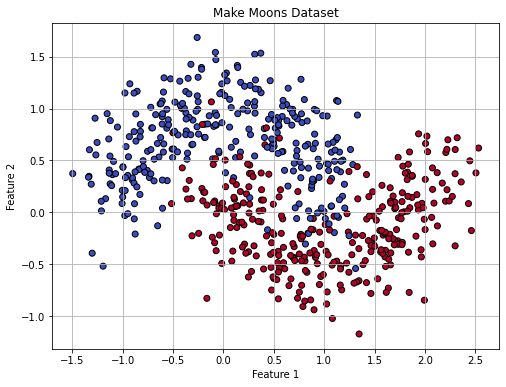

In [35]:
# Visualize:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="black"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Make Moons Dataset")
plt.grid(True)
plt.show()

In [36]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 480
Testing samples: 120


In [37]:
# Create an SVM pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

In [38]:
# Define the hyperparameter grid
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.01, 0.1, 1, 10]
}

In [39]:
# Perform 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-validation F1:", grid_search.best_score_)

Best Parameters: {'svm__C': 10, 'svm__gamma': 1}
Best Cross-validation F1: 0.9487700634565137


In [40]:
# Create the results table
cv_results = pd.DataFrame(grid_search.cv_results_)

results_df = cv_results[
    [
        "param_svm__C",
        "param_svm__gamma",
        "mean_train_score",
        "mean_test_score",
        "std_test_score"
    ]
].copy()

results_df.columns = [
    "C",
    "Gamma",
    "Mean Train F1",
    "Mean CV F1",
    "CV F1 Std"
]

results_df

,C,Gamma,Mean Train F1,Mean CV F1,CV F1 Std
0,0.1,0.01,0.848228,0.844188,0.045544
1,0.1,0.10,0.856153,0.852968,0.050263
2,0.1,1.00,0.913506,0.914589,0.020167
3,0.1,10.00,0.952224,0.939701,0.018115
4,1.0,0.01,0.856193,0.851686,0.050255
5,1.0,0.10,0.876346,0.873783,0.023445
6,1.0,1.00,0.940947,0.932054,0.018835
7,1.0,10.00,0.954535,0.940468,0.021090
8,10.0,0.01,0.861233,0.856308,0.044964
9,10.0,0.10,0.910389,0.910432,0.028659


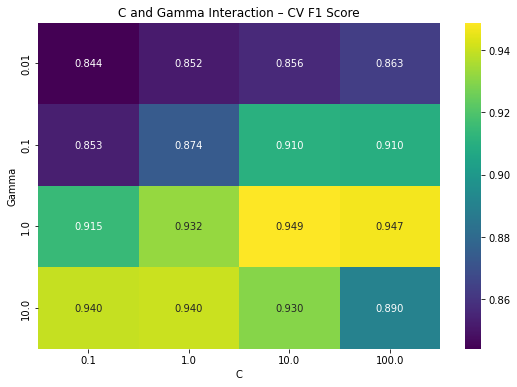

In [41]:
# Plot the C and Gamma heatmap
heatmap_data = results_df.pivot(
    index="Gamma",
    columns="C",
    values="Mean CV F1"
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="viridis"
)

plt.title("C and Gamma Interaction – CV F1 Score")
plt.xlabel("C")
plt.ylabel("Gamma")
plt.show()

In [42]:
# Compare decision boundaries
selected_parameters = [
    {"svm__C": 0.1, "svm__gamma": 0.01},
    {"svm__C": 1, "svm__gamma": 1},
    {"svm__C": 100, "svm__gamma": 10}
]

def plot_rbf_boundary(model, X, y, title):

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    Z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 5))

    plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        cmap="coolwarm",
        edgecolors="black",
        s=25
    )

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)
    plt.show()

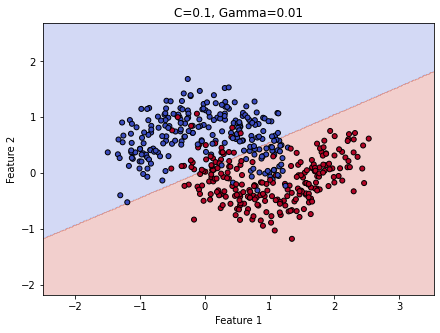

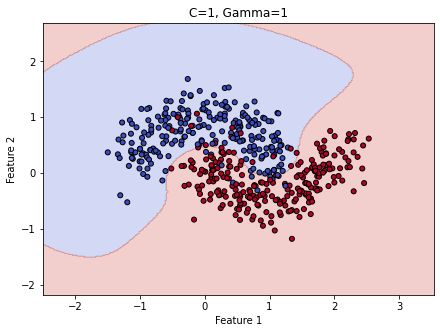

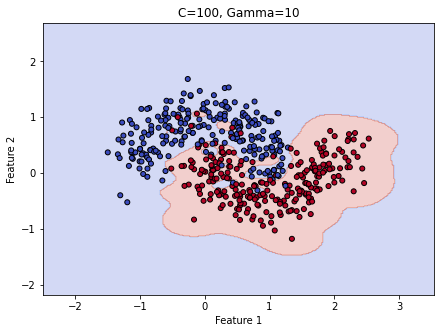

In [44]:
# Train and visualize:
for params in selected_parameters:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="rbf",
            C=params["svm__C"],
            gamma=params["svm__gamma"]
        ))
    ])

    model.fit(X_train, y_train)

    plot_rbf_boundary(
        model,
        X_train,
        y_train,
        f"C={params['svm__C']}, Gamma={params['svm__gamma']}"
    )

In [45]:
# Evaluate the best model on the test set
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test F1 Score:", f1_score(y_test, y_pred))

Test Accuracy: 0.9333333333333333
Test F1 Score: 0.9333333333333333


In [ ]:
Problem 4 – Kernel Comparison

In [46]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_classification, make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

In [47]:
# Generate three datasets
# Dataset A: Blobs
X_blobs, y_blobs = make_blobs(
    n_samples=400,
    centers=2,
    n_features=2,
    cluster_std=1.2,
    random_state=42
)

In [48]:
# Dataset B: XOR
rng = np.random.RandomState(42)

X_xor = rng.uniform(-2, 2, size=(400, 2))

y_xor = (
    (X_xor[:, 0] * X_xor[:, 1]) > 0
).astype(int)

In [49]:
# Dataset C: Circles
X_circles, y_circles = make_circles(
    n_samples=400,
    noise=0.08,
    factor=0.4,
    random_state=42
)

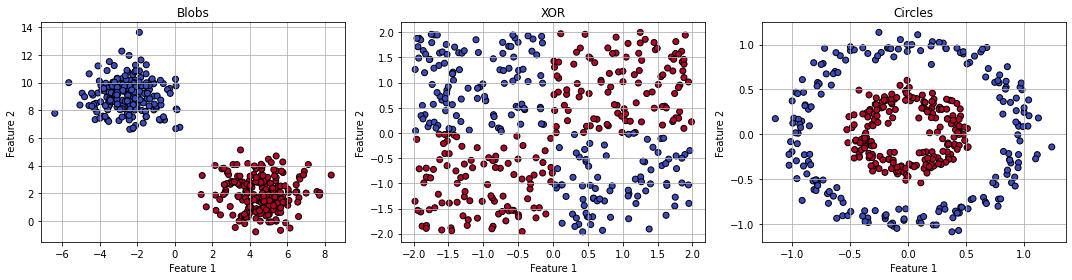

In [50]:
# Visualize the datasets
datasets = [
    ("Blobs", X_blobs, y_blobs),
    ("XOR", X_xor, y_xor),
    ("Circles", X_circles, y_circles)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, X, y) in zip(axes, datasets):

    ax.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        cmap="coolwarm",
        edgecolors="black"
    )

    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [51]:
# Create a function to train and evaluate SVM models
def evaluate_kernel_models(X, y, dataset_name):

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    kernels = ["linear", "poly", "rbf"]

    results = []
    trained_models = {}

    for kernel in kernels:

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("svm", SVC(
                kernel=kernel,
                C=1,
                gamma="scale",
                degree=3
            ))
        ])

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        results.append({
            "Dataset": dataset_name,
            "Kernel": kernel,
            "Accuracy": accuracy_score(y_test, y_pred),
            "F1 Score": f1_score(y_test, y_pred)
        })

        trained_models[kernel] = model

    return pd.DataFrame(results), trained_models, X_train, y_train

In [52]:
# Compare kernels on all three datasets
all_results = []

dataset_models = {}

for name, X, y in datasets:

    result, models, X_train, y_train = evaluate_kernel_models(
        X, y, name
    )

    all_results.append(result)

    dataset_models[name] = {
        "models": models,
        "X_train": X_train,
        "y_train": y_train
    }

comparison_df = pd.concat(
    all_results,
    ignore_index=True
)

comparison_df

,Dataset,Kernel,Accuracy,F1 Score
0,Blobs,linear,1.0000,1.000000
1,Blobs,poly,0.9875,0.987654
2,Blobs,rbf,1.0000,1.000000
3,XOR,linear,0.7125,0.767677
4,XOR,poly,0.6000,0.652174
5,XOR,rbf,0.9500,0.950000
6,Circles,linear,0.5625,0.660194
7,Circles,poly,0.6125,0.720721
8,Circles,rbf,1.0000,1.000000


In [53]:
# Plot decision boundaries
def plot_decision_boundary(model, X, y, title):

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    Z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 5))

    plt.contourf(
        xx,
        yy,
        Z,
        alpha=0.25,
        cmap="coolwarm"
    )

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        cmap="coolwarm",
        edgecolors="black",
        s=25
    )

    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

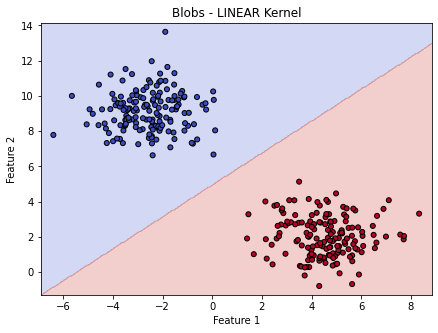

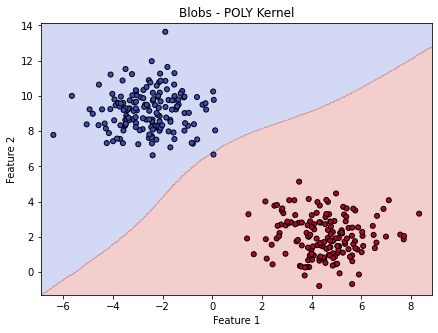

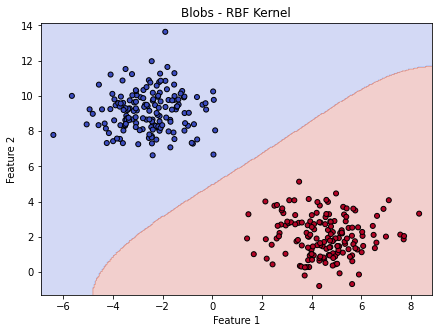

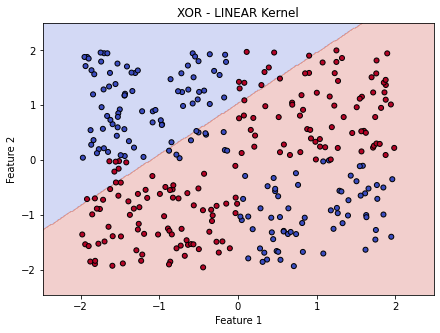

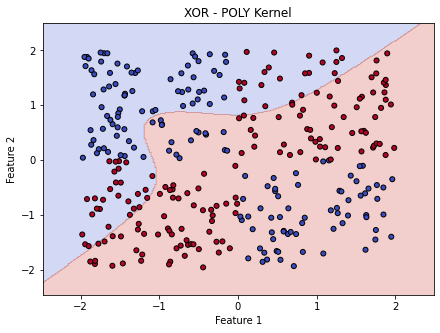

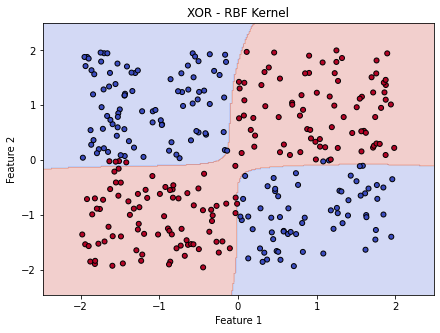

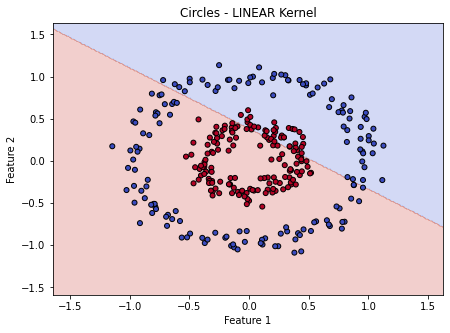

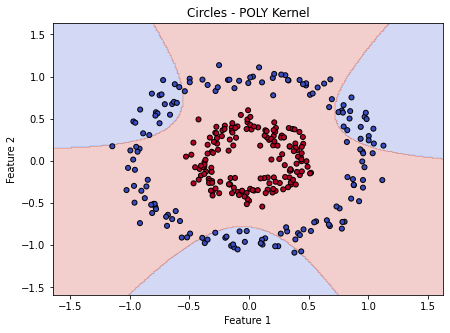

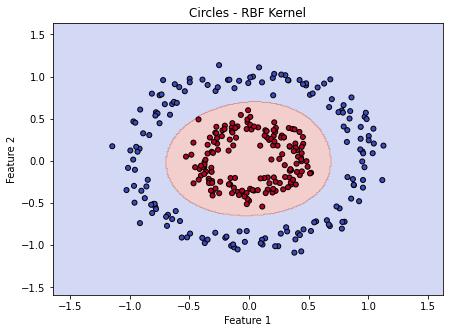

In [54]:
# Plot each kernel for each dataset:
for dataset_name in dataset_models:

    data = dataset_models[dataset_name]

    for kernel, model in data["models"].items():

        plot_decision_boundary(
            model,
            data["X_train"],
            data["y_train"],
            f"{dataset_name} - {kernel.upper()} Kernel"
        )

In [55]:
# Engineer a feature for XOR
def add_xor_feature(X):

    interaction = (
        X[:, 0] * X[:, 1]
    ).reshape(-1, 1)

    return np.column_stack([
        X,
        interaction
    ])

In [56]:
# Transform the XOR data:
X_xor_engineered = add_xor_feature(X_xor)

print("Original shape:", X_xor.shape)
print("Engineered shape:", X_xor_engineered.shape)

Original shape: (400, 2)
Engineered shape: (400, 3)


In [57]:
# Train a linear SVM on the engineered features:
X_train, X_test, y_train, y_test = train_test_split(
    X_xor_engineered,
    y_xor,
    test_size=0.20,
    random_state=42,
    stratify=y_xor
)

xor_linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1))
])

xor_linear_model.fit(X_train, y_train)

y_pred = xor_linear_model.predict(X_test)

print("Engineered XOR Accuracy:", accuracy_score(y_test, y_pred))
print("Engineered XOR F1:", f1_score(y_test, y_pred))

Engineered XOR Accuracy: 0.9875
Engineered XOR F1: 0.9879518072289156


In [58]:
# Compare XOR before and after feature engineering
xor_comparison = pd.DataFrame({
    "Approach": [
        "Linear SVM - Original Features",
        "Linear SVM - Engineered Feature",
        "RBF SVM - Original Features"
    ],
    "Accuracy": [
        comparison_df[
            (comparison_df["Dataset"] == "XOR") &
            (comparison_df["Kernel"] == "linear")
        ]["Accuracy"].iloc[0],

        accuracy_score(y_test, y_pred),

        comparison_df[
            (comparison_df["Dataset"] == "XOR") &
            (comparison_df["Kernel"] == "rbf")
        ]["Accuracy"].iloc[0]
    ]
})

xor_comparison

,Approach,Accuracy
0,Linear SVM - Original Features,0.7125
1,Linear SVM - Engineered Feature,0.9875
2,RBF SVM - Original Features,0.9500


In [ ]:
Problem 5 – Support Vector Influence

In [59]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [60]:
# Generate the dataset
X, y = make_classification(
    n_samples=400,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.2,
    flip_y=0.03,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 300
Testing samples: 100


In [61]:
# Train the original SVM
original_model = SVC(
    kernel="linear",
    C=1
)

original_model.fit(X_train, y_train)

original_predictions = original_model.predict(X_test)

print("Original accuracy:", accuracy_score(y_test, original_predictions))
print("Number of support vectors:", len(original_model.support_vectors_))
print("Support vector indices:", original_model.support_)

Original accuracy: 0.87
Number of support vectors: 73
Support vector indices: [  4  12  15  18  39  62  65  66  73  74  86  87 100 105 106 119 126 137
 143 154 162 166 185 192 201 205 215 226 231 234 257 272 278 280 287 289
 291   3  27  61  72  78  81  88  89  94  98 110 115 117 120 121 125 157
 158 168 177 180 181 184 196 212 213 217 219 221 223 232 243 246 264 271
 288]


In [62]:
# Identify support vectors
support_indices = original_model.support_

support_mask = np.zeros(len(X_train), dtype=bool)
support_mask[support_indices] = True

non_support_indices = np.where(~support_mask)[0]

print("Support vectors:", len(support_indices))
print("Non-support vectors:", len(non_support_indices))

Support vectors: 73
Non-support vectors: 227


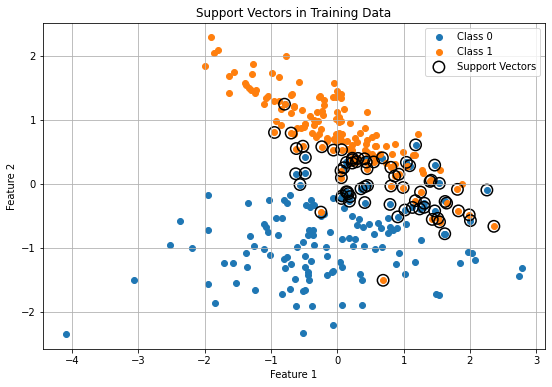

In [63]:
# Visualize them:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_train[y_train == 0, 0],
    X_train[y_train == 0, 1],
    label="Class 0"
)

plt.scatter(
    X_train[y_train == 1, 0],
    X_train[y_train == 1, 1],
    label="Class 1"
)

plt.scatter(
    X_train[support_indices, 0],
    X_train[support_indices, 1],
    s=130,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Support Vectors"
)

plt.title("Support Vectors in Training Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

In [64]:
# Create a decision boundary plotting function
def plot_boundary(model, X, y, title):

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    Z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(xx, yy, Z, alpha=0.2, cmap="coolwarm")

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        cmap="coolwarm",
        edgecolors="black",
        s=25
    )

    plt.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        facecolors="none",
        edgecolors="black",
        s=120,
        linewidths=1.5,
        label="Support Vectors"
    )

    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    plt.grid(True)
    plt.show()

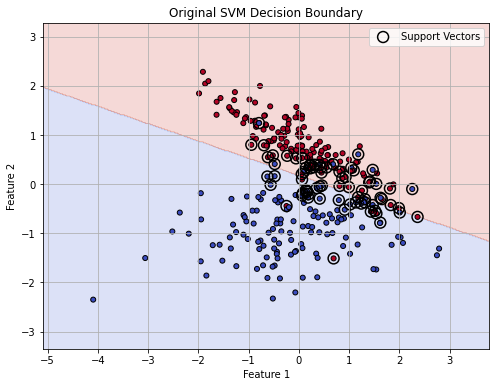

In [65]:
# Plot the original model:
plot_boundary(
    original_model,
    X_train,
    y_train,
    "Original SVM Decision Boundary"
)

In [66]:
# Experiment A: Remove support vectors
rng = np.random.RandomState(42)

num_remove = max(1, int(0.25 * len(support_indices)))

removed_sv_indices = rng.choice(
    support_indices,
    size=num_remove,
    replace=False
)

keep_mask = np.ones(len(X_train), dtype=bool)
keep_mask[removed_sv_indices] = False

X_without_sv = X_train[keep_mask]
y_without_sv = y_train[keep_mask]

model_without_sv = SVC(
    kernel="linear",
    C=1
)

model_without_sv.fit(X_without_sv, y_without_sv)

pred_without_sv = model_without_sv.predict(X_test)

print("Accuracy after removing support vectors:",
      accuracy_score(y_test, pred_without_sv))

print("Remaining support vectors:",
      len(model_without_sv.support_vectors_))

Accuracy after removing support vectors: 0.87
Remaining support vectors: 56


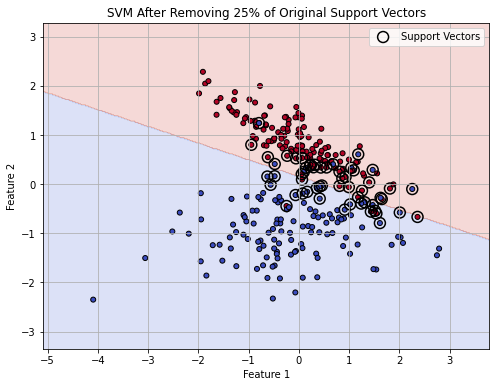

In [67]:
# Visualize:
plot_boundary(
    model_without_sv,
    X_without_sv,
    y_without_sv,
    "SVM After Removing 25% of Original Support Vectors"
)

In [68]:
# Experiment B: Remove non-support vectors
num_remove_non_sv = max(
    1,
    int(0.25 * len(non_support_indices))
)

removed_non_sv = rng.choice(
    non_support_indices,
    size=num_remove_non_sv,
    replace=False
)

keep_mask_non_sv = np.ones(len(X_train), dtype=bool)
keep_mask_non_sv[removed_non_sv] = False

X_without_non_sv = X_train[keep_mask_non_sv]
y_without_non_sv = y_train[keep_mask_non_sv]

model_without_non_sv = SVC(
    kernel="linear",
    C=1
)

model_without_non_sv.fit(
    X_without_non_sv,
    y_without_non_sv
)

pred_without_non_sv = model_without_non_sv.predict(X_test)

print(
    "Accuracy after removing non-support vectors:",
    accuracy_score(y_test, pred_without_non_sv)
)

Accuracy after removing non-support vectors: 0.87


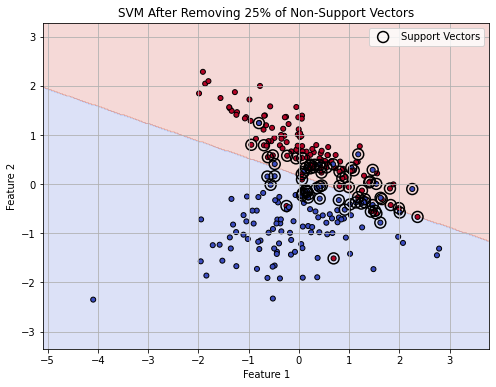

In [69]:
# Visualize:
plot_boundary(
    model_without_non_sv,
    X_without_non_sv,
    y_without_non_sv,
    "SVM After Removing 25% of Non-Support Vectors"
)

In [70]:
# Experiment C: Move a support vector
X_moved = X_train.copy()

selected_sv = support_indices[0]

print("Original position:", X_moved[selected_sv])

X_moved[selected_sv] += np.array([2.0, 2.0])

print("New position:", X_moved[selected_sv])

Original position: [ 1.6202973 -0.7831021]
New position: [3.6202973 1.2168979]


In [71]:
# Train the modified model:
model_moved = SVC(
    kernel="linear",
    C=1
)

model_moved.fit(X_moved, y_train)

pred_moved = model_moved.predict(X_test)

print(
    "Accuracy after moving support vector:",
    accuracy_score(y_test, pred_moved)
)

Accuracy after moving support vector: 0.86


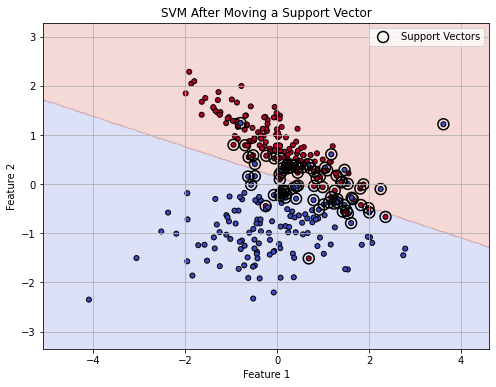

In [72]:
# Visualize:
plot_boundary(
    model_moved,
    X_moved,
    y_train,
    "SVM After Moving a Support Vector"
)

In [73]:
# Compare all experiments
comparison = pd.DataFrame({
    "Experiment": [
        "Original",
        "Remove Support Vectors",
        "Remove Non-Support Vectors",
        "Move Support Vector"
    ],
    "Test Accuracy": [
        accuracy_score(y_test, original_predictions),
        accuracy_score(y_test, pred_without_sv),
        accuracy_score(y_test, pred_without_non_sv),
        accuracy_score(y_test, pred_moved)
    ],
    "Support Vector Count": [
        len(original_model.support_vectors_),
        len(model_without_sv.support_vectors_),
        len(model_without_non_sv.support_vectors_),
        len(model_moved.support_vectors_)
    ]
})

comparison

,Experiment,Test Accuracy,Support Vector Count
0,Original,0.87,73
1,Remove Support Vectors,0.87,56
2,Remove Non-Support Vectors,0.87,73
3,Move Support Vector,0.86,78


In [ ]:
Problem 6 – Feature Scaling in SVM

In [74]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [75]:
# Generate industrial sensor data
X, y = make_classification(
    n_samples=1000,
    n_features=4,
    n_informative=3,
    n_redundant=0,
    n_clusters_per_class=2,
    class_sep=1.0,
    random_state=42
)

# Simulate different sensor measurement scales
X[:, 0] *= 10
X[:, 1] *= 100
X[:, 2] *= 1000
X[:, 3] *= 10000

feature_names = [
    "Temperature",
    "Pressure",
    "Vibration",
    "Production_Load"
]

sensor_df = pd.DataFrame(X, columns=feature_names)
sensor_df["Defect"] = y

sensor_df.head()

,Temperature,Pressure,Vibration,Production_Load,Defect
0,11.701987,-111.019852,790.987571,-9100.813809,0
1,1.986800,149.922109,4.205239,9881.233669,1
2,16.957229,12.673445,69.711094,2223.489255,1
3,-5.314546,-16.927020,-1100.361893,-22247.866557,0
4,1.940519,-247.934266,297.014308,15185.221714,0


In [76]:
# Inspect feature ranges:
sensor_df.describe()

,Temperature,Pressure,Vibration,Production_Load,Defect
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,-0.191058,0.948628,482.059901,-5018.635466,0.499000
std,10.259633,119.862608,1284.558885,12498.262499,0.500249
min,-29.294487,-395.059571,-3778.977764,-38372.309849,0.000000
25%,-7.426374,-95.395944,-199.754901,-13119.253551,0.000000
50%,-0.047244,20.739976,620.634840,-7255.159768,0.000000
75%,6.733812,95.697443,1371.884049,2682.586770,1.000000
max,32.430930,286.085952,3841.187896,46195.244882,1.000000


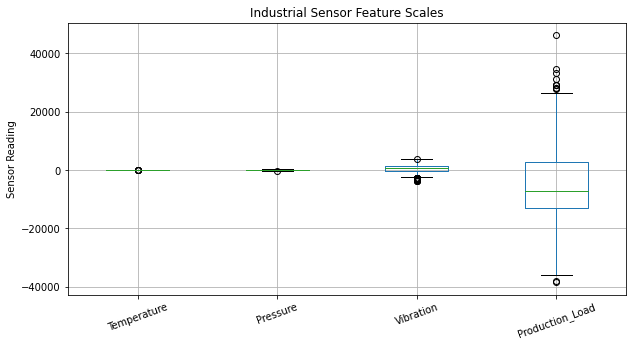

In [77]:
# Visualize the feature distributions:
sensor_df[feature_names].boxplot(figsize=(10, 5))

plt.title("Industrial Sensor Feature Scales")
plt.ylabel("Sensor Reading")
plt.xticks(rotation=20)
plt.show()

In [78]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 750
Testing samples: 250


In [79]:
# Train models without scaling
unscaled_results = []

unscaled_models = {}

for kernel in ["linear", "rbf"]:

    model = SVC(
        kernel=kernel,
        C=1,
        gamma="scale"
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    unscaled_results.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

    unscaled_models[kernel] = model

unscaled_df = pd.DataFrame(unscaled_results)

unscaled_df

,Kernel,Accuracy,Precision,Recall,F1 Score
0,linear,0.892,0.895161,0.888,0.891566
1,rbf,0.808,0.859813,0.736,0.793103


In [80]:
# Train models with StandardScaler
scaled_results = []

scaled_models = {}

for kernel in ["linear", "rbf"]:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel=kernel,
            C=1,
            gamma="scale"
        ))
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    scaled_results.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

    scaled_models[kernel] = model

scaled_df = pd.DataFrame(scaled_results)

scaled_df

,Kernel,Accuracy,Precision,Recall,F1 Score
0,linear,0.896,0.889764,0.904,0.896825
1,rbf,0.920,0.906977,0.936,0.921260


In [81]:
# Compare scaled and unscaled models
comparison = pd.concat([
    unscaled_df.assign(Scaling="Without Scaling"),
    scaled_df.assign(Scaling="With StandardScaler")
], ignore_index=True)

comparison = comparison[
    ["Kernel", "Scaling", "Accuracy", "Precision", "Recall", "F1 Score"]
]

comparison

,Kernel,Scaling,Accuracy,Precision,Recall,F1 Score
0,linear,Without Scaling,0.892,0.895161,0.888,0.891566
1,rbf,Without Scaling,0.808,0.859813,0.736,0.793103
2,linear,With StandardScaler,0.896,0.889764,0.904,0.896825
3,rbf,With StandardScaler,0.920,0.906977,0.936,0.921260


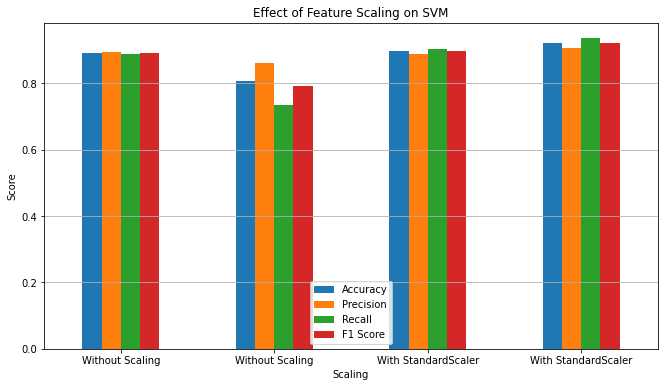

In [82]:
# Visualize:
comparison.plot(
    x="Scaling",
    y=["Accuracy", "Precision", "Recall", "F1 Score"],
    kind="bar",
    figsize=(11, 6)
)

plt.title("Effect of Feature Scaling on SVM")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [83]:
# Tune hyperparameters using a pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.01, 0.1, 1, 10, 100]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": [0.001, 0.01, 0.1, 1, 10]
    }
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)

Best Parameters: {'svm__C': 1, 'svm__gamma': 1, 'svm__kernel': 'rbf'}
Best CV F1: 0.9614187221304007


In [84]:
# Evaluate:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test Precision:", precision_score(y_test, y_pred))
print("Test Recall:", recall_score(y_test, y_pred))
print("Test F1:", f1_score(y_test, y_pred))

Test Accuracy: 0.936
Test Precision: 0.9224806201550387
Test Recall: 0.952
Test F1: 0.937007874015748


In [85]:
# Demonstrate inconsistent deployment preprocessing
# Correct prediction through the complete pipeline
correct_predictions = best_model.predict(X_test)

# Incorrect: bypass the scaler and send raw readings to the SVM
incorrect_predictions = best_model.named_steps["svm"].predict(X_test)

print(
    "Correct deployment accuracy:",
    accuracy_score(y_test, correct_predictions)
)

print(
    "Incorrect deployment accuracy:",
    accuracy_score(y_test, incorrect_predictions)
)

Correct deployment accuracy: 0.936
Incorrect deployment accuracy: 0.5


In [ ]:
Problem 7 – Rare Manufacturing Defects

In [86]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve
)

In [87]:
# Generate an imbalanced dataset
X, y = make_classification(
    n_samples=5000,
    n_features=5,
    n_informative=4,
    n_redundant=0,
    n_clusters_per_class=2,
    weights=[0.98, 0.02],
    flip_y=0.01,
    random_state=42
)

print("Dataset shape:", X.shape)
print("\nClass distribution:")
print(pd.Series(y).value_counts())

print("\nDefect percentage:", (y == 1).mean() * 100)

Dataset shape: (5000, 5)

Class distribution:
0    4857
1     143
Name: count, dtype: int64

Defect percentage: 2.86


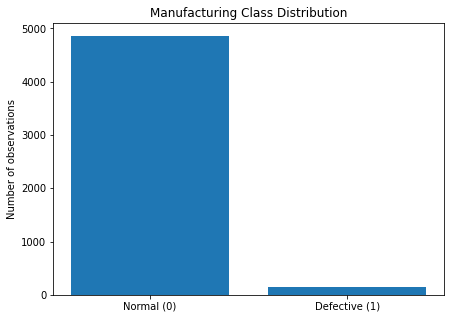

In [88]:
# Visualize class imbalance
class_counts = pd.Series(y).value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Normal (0)", "Defective (1)"],
    class_counts.values
)

plt.ylabel("Number of observations")
plt.title("Manufacturing Class Distribution")
plt.show()

In [89]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting distribution:")
print(pd.Series(y_test).value_counts())

Training distribution:
0    3643
1     107
Name: count, dtype: int64

Testing distribution:
0    1214
1      36
Name: count, dtype: int64


In [90]:
# Train a standard SVM
standard_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1,
        gamma="scale"
    ))
])

standard_svm.fit(X_train, y_train)

standard_predictions = standard_svm.predict(X_test)
standard_scores = standard_svm.decision_function(X_test)

In [91]:
# Train a class-weighted SVM
balanced_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1,
        gamma="scale",
        class_weight="balanced"
    ))
])

balanced_svm.fit(X_train, y_train)

balanced_predictions = balanced_svm.predict(X_test)
balanced_scores = balanced_svm.decision_function(X_test)

In [92]:
# Compare evaluation metrics
def evaluate_model(y_true, predictions, scores, model_name):

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1 Score": f1_score(y_true, predictions, zero_division=0),
        "Average Precision": average_precision_score(y_true, scores)
    }


results = pd.DataFrame([
    evaluate_model(
        y_test,
        standard_predictions,
        standard_scores,
        "Standard SVM"
    ),
    evaluate_model(
        y_test,
        balanced_predictions,
        balanced_scores,
        "Balanced SVM"
    )
])

results

,Model,Accuracy,Precision,Recall,F1 Score,Average Precision
0,Standard SVM,0.9784,1.000000,0.250000,0.4,0.563090
1,Balanced SVM,0.8720,0.121951,0.555556,0.2,0.314483


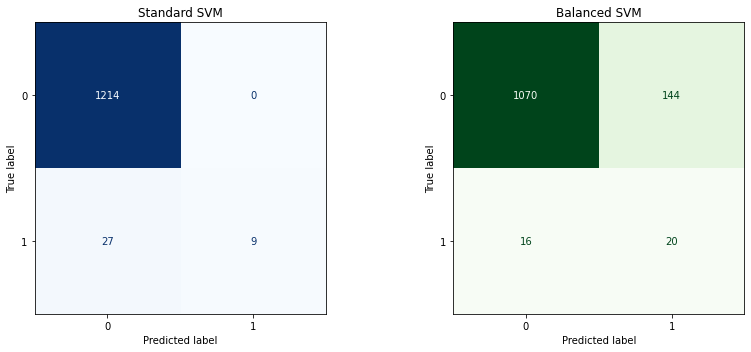

In [93]:
# Compare confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    standard_predictions,
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)

axes[0].set_title("Standard SVM")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    balanced_predictions,
    ax=axes[1],
    cmap="Greens",
    colorbar=False
)

axes[1].set_title("Balanced SVM")

plt.tight_layout()
plt.show()

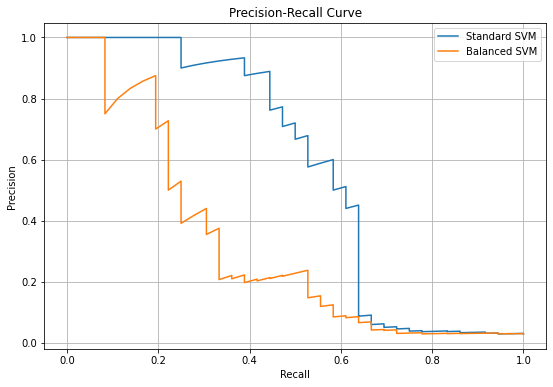

In [94]:
# Plot Precision-Recall curves
precision_standard, recall_standard, _ = precision_recall_curve(
    y_test,
    standard_scores
)

precision_balanced, recall_balanced, _ = precision_recall_curve(
    y_test,
    balanced_scores
)

plt.figure(figsize=(9, 6))

plt.plot(
    recall_standard,
    precision_standard,
    label="Standard SVM"
)

plt.plot(
    recall_balanced,
    precision_balanced,
    label="Balanced SVM"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.show()

In [95]:
# Compare classification reports
print("STANDARD SVM")
print(classification_report(
    y_test,
    standard_predictions,
    zero_division=0
))

print("\nBALANCED SVM")
print(classification_report(
    y_test,
    balanced_predictions,
    zero_division=0
))

STANDARD SVM
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1214
           1       1.00      0.25      0.40        36

    accuracy                           0.98      1250
   macro avg       0.99      0.62      0.69      1250
weighted avg       0.98      0.98      0.97      1250


BALANCED SVM
              precision    recall  f1-score   support

           0       0.99      0.88      0.93      1214
           1       0.12      0.56      0.20        36

    accuracy                           0.87      1250
   macro avg       0.55      0.72      0.57      1250
weighted avg       0.96      0.87      0.91      1250



In [ ]:
Problem 8 – Threshold Selection for Manufacturing Inspection

In [96]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    accuracy_score
)

In [97]:
# Generate the dataset
X, y = make_classification(
    n_samples=5000,
    n_features=6,
    n_informative=4,
    n_redundant=0,
    weights=[0.95, 0.05],
    flip_y=0.01,
    random_state=42
)

print("Dataset shape:", X.shape)
print("Class distribution:")
print(pd.Series(y).value_counts())

Dataset shape: (5000, 6)
Class distribution:
0    4732
1     268
Name: count, dtype: int64


In [98]:
# Split into training, validation and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 3000
Validation: 1000
Testing: 1000


In [99]:
# Train an RBF SVM
base_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1,
        gamma="scale"
    ))
])

base_model.fit(X_train, y_train)

print("SVM training completed.")

SVM training completed.


In [100]:
# Calibrate the SVM probabilities
calibrated_model = CalibratedClassifierCV(
    estimator=base_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train, y_train)

val_probabilities = calibrated_model.predict_proba(X_val)[:, 1]
test_probabilities = calibrated_model.predict_proba(X_test)[:, 1]

print("Sample validation probabilities:")
print(val_probabilities[:10])

Sample validation probabilities:
[0.00643924 0.03587622 0.00429878 0.0140353  0.01746753 0.00813543
 0.01095316 0.0117697  0.00880772 0.03663444]


In [101]:
# Define business costs and constraints
MISS_COST = 500
FALSE_ALARM_COST = 10
MAX_INSPECTION_RATE = 0.08

In [102]:
# Evaluate different thresholds
def evaluate_threshold(y_true, probabilities, threshold):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    inspection_rate = np.mean(predictions == 1)

    total_cost = (
        fn * MISS_COST +
        fp * FALSE_ALARM_COST
    )

    return {
        "Threshold": threshold,
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Inspection Rate": inspection_rate,
        "Total Cost": total_cost,
        "Cost per 1000": total_cost / len(y_true) * 1000
    }

In [103]:
# Evaluate thresholds:
thresholds = np.linspace(0.01, 0.99, 99)

threshold_results = []

for threshold in thresholds:

    threshold_results.append(
        evaluate_threshold(
            y_val,
            val_probabilities,
            threshold
        )
    )

threshold_df = pd.DataFrame(threshold_results)

threshold_df.head()

,Threshold,Precision,Recall,F1,TP,FP,FN,TN,Inspection Rate,Total Cost,Cost per 1000
0,0.01,0.073906,0.924528,0.136872,49,614,4,333,0.663,8140,8140.0
1,0.02,0.109785,0.867925,0.194915,46,373,7,574,0.419,7230,7230.0
2,0.03,0.172691,0.811321,0.284768,43,206,10,741,0.249,7060,7060.0
3,0.04,0.238636,0.792453,0.366812,42,134,11,813,0.176,6840,6840.0
4,0.05,0.327869,0.754717,0.457143,40,82,13,865,0.122,7320,7320.0


In [104]:
# Find the best threshold satisfying the inspection constraint
feasible_thresholds = threshold_df[
    threshold_df["Inspection Rate"] <= MAX_INSPECTION_RATE
]

if feasible_thresholds.empty:
    print("No threshold satisfies the inspection constraint.")

else:
    best_row = feasible_thresholds.loc[
        feasible_thresholds["Total Cost"].idxmin()
    ]

    best_threshold = best_row["Threshold"]

    print("Selected Threshold:", best_threshold)
    print("Validation Inspection Rate:", best_row["Inspection Rate"])
    print("Validation Total Cost:", best_row["Total Cost"])
    print("Validation Recall:", best_row["Recall"])
    print("Validation Precision:", best_row["Precision"])

Selected Threshold: 0.09
Validation Inspection Rate: 0.065
Validation Total Cost: 9300.0
Validation Recall: 0.660377358490566
Validation Precision: 0.5384615384615384


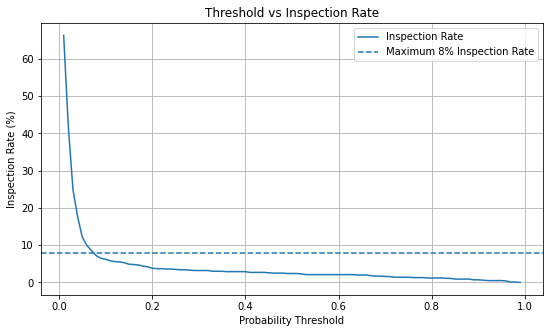

In [105]:
# Plot threshold versus inspection rate
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Inspection Rate"] * 100,
    label="Inspection Rate"
)

plt.axhline(
    MAX_INSPECTION_RATE * 100,
    linestyle="--",
    label="Maximum 8% Inspection Rate"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Inspection Rate (%)")
plt.title("Threshold vs Inspection Rate")
plt.legend()
plt.grid(True)
plt.show()

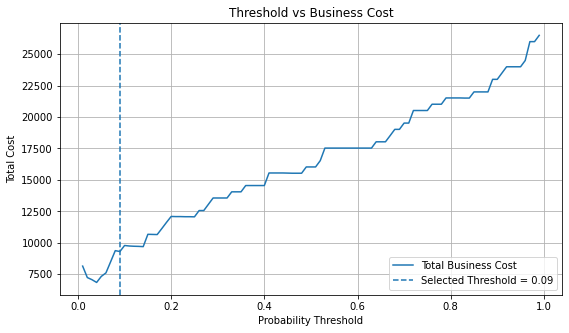

In [106]:
# Plot threshold versus total cost
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Total Cost"],
    label="Total Business Cost"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected Threshold = {best_threshold:.2f}"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Total Cost")
plt.title("Threshold vs Business Cost")
plt.legend()
plt.grid(True)
plt.show()

In [107]:
# Evaluate the selected threshold on the test set
test_results = evaluate_threshold(
    y_test,
    test_probabilities,
    best_threshold
)

print(pd.Series(test_results))

Threshold             0.090000
Precision             0.567568
Recall                0.777778
F1                    0.656250
TP                   42.000000
FP                   32.000000
FN                   12.000000
TN                  914.000000
Inspection Rate       0.074000
Total Cost         6320.000000
Cost per 1000      6320.000000
dtype: float64


In [108]:
# Compare default threshold with selected threshold
default_results = evaluate_threshold(
    y_test,
    test_probabilities,
    0.50
)

comparison = pd.DataFrame([
    {"Model": "Default Threshold (0.50)", **default_results},
    {"Model": "Selected Threshold", **test_results}
])

comparison[
    [
        "Model",
        "Precision",
        "Recall",
        "F1",
        "Inspection Rate",
        "Total Cost",
        "Cost per 1000"
    ]
]

,Model,Precision,Recall,F1,Inspection Rate,Total Cost,Cost per 1000
0,Default Threshold (0.50),0.781250,0.462963,0.581395,0.032,14570,14570.0
1,Selected Threshold,0.567568,0.777778,0.656250,0.074,6320,6320.0


In [ ]:
Problem 10: One-Class SVM anomaly detection

In [109]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

In [110]:
# Generate synthetic manufacturing data
np.random.seed(42)

# Normal operating regime 1
safe_1 = np.random.normal(
    loc=[0, 0],
    scale=[0.7, 0.7],
    size=(500, 2)
)

# Normal operating regime 2
safe_2 = np.random.normal(
    loc=[3, 3],
    scale=[0.7, 0.7],
    size=(500, 2)
)

# Fault regime
faults = np.random.normal(
    loc=[1.5, 5],
    scale=[0.6, 0.6],
    size=(100, 2)
)

X_safe = np.vstack([safe_1, safe_2])
X_all = np.vstack([safe_1, safe_2, faults])

# Labels: 1 = safe, -1 = anomaly
y_true = np.array(
    [1] * len(X_safe) + [-1] * len(faults)
)

print("Safe observations:", len(X_safe))
print("Fault observations:", len(faults))
print("Total observations:", len(X_all))

Safe observations: 1000
Fault observations: 100
Total observations: 1100


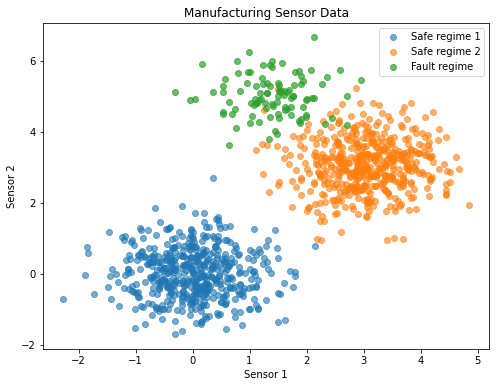

In [111]:
# Visualize the data
plt.figure(figsize=(8, 6))

plt.scatter(
    safe_1[:, 0], safe_1[:, 1],
    label="Safe regime 1", alpha=0.6
)

plt.scatter(
    safe_2[:, 0], safe_2[:, 1],
    label="Safe regime 2", alpha=0.6
)

plt.scatter(
    faults[:, 0], faults[:, 1],
    label="Fault regime", alpha=0.7
)

plt.xlabel("Sensor 1")
plt.ylabel("Sensor 2")
plt.title("Manufacturing Sensor Data")
plt.legend()
plt.show()

In [112]:
# Train One-Class SVM
scaler = StandardScaler()

X_safe_scaled = scaler.fit_transform(X_safe)
X_all_scaled = scaler.transform(X_all)

model = OneClassSVM(
    kernel="rbf",
    nu=0.05,
    gamma="scale"
)

model.fit(X_safe_scaled)

predictions = model.predict(X_all_scaled)

print("Predictions:", np.unique(predictions))

Predictions: [-1  1]


In [113]:
# Evaluate anomaly detection
cm = confusion_matrix(
    y_true,
    predictions,
    labels=[1, -1]
)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        predictions,
        labels=[1, -1],
        target_names=["Safe", "Anomaly"],
        zero_division=0
    )
)

Confusion Matrix:
[[951  49]
 [  3  97]]

Classification Report:
              precision    recall  f1-score   support

        Safe       1.00      0.95      0.97      1000
     Anomaly       0.66      0.97      0.79       100

    accuracy                           0.95      1100
   macro avg       0.83      0.96      0.88      1100
weighted avg       0.97      0.95      0.96      1100



In [114]:
# Calculate false alarm rates for each safe regime
pred_safe_1 = model.predict(
    scaler.transform(safe_1)
)

pred_safe_2 = model.predict(
    scaler.transform(safe_2)
)

false_alarm_1 = np.mean(pred_safe_1 == -1)
false_alarm_2 = np.mean(pred_safe_2 == -1)

print(f"Regime 1 false alarm rate: {false_alarm_1:.2%}")
print(f"Regime 2 false alarm rate: {false_alarm_2:.2%}")

Regime 1 false alarm rate: 5.00%
Regime 2 false alarm rate: 4.80%


In [115]:
# Investigate nu and gamma
nu_values = [0.01, 0.05, 0.10, 0.20]
gamma_values = ["scale", 0.1, 1, 5]

results = []

for nu in nu_values:
    for gamma in gamma_values:

        svm = OneClassSVM(
            kernel="rbf",
            nu=nu,
            gamma=gamma
        )

        svm.fit(X_safe_scaled)

        safe_predictions = svm.predict(X_safe_scaled)
        fault_predictions = svm.predict(
            scaler.transform(faults)
        )

        false_alarm_rate = np.mean(
            safe_predictions == -1
        )

        anomaly_detection_rate = np.mean(
            fault_predictions == -1
        )

        results.append({
            "nu": nu,
            "gamma": gamma,
            "False Alarm Rate": false_alarm_rate,
            "Anomaly Detection Rate": anomaly_detection_rate
        })

results_df = pd.DataFrame(results)

display(results_df)

,nu,gamma,False Alarm Rate,Anomaly Detection Rate
0,0.01,scale,0.010,0.69
1,0.01,0.1,0.010,0.67
2,0.01,1,0.009,0.57
3,0.01,5,0.139,0.65
4,0.05,scale,0.049,0.97
5,0.05,0.1,0.051,0.90
6,0.05,1,0.052,0.97
7,0.05,5,0.091,0.97
8,0.10,scale,0.101,0.97
9,0.10,0.1,0.102,0.96


In [116]:
# Test an unseen safe operating regime
unseen_safe = np.random.normal(
    loc=[5, 0],
    scale=[0.5, 0.5],
    size=(200, 2)
)

unseen_scaled = scaler.transform(unseen_safe)

unseen_predictions = model.predict(unseen_scaled)

unseen_false_alarm_rate = np.mean(
    unseen_predictions == -1
)

print(
    "Unseen safe regime false alarm rate:",
    f"{unseen_false_alarm_rate:.2%}"
)

Unseen safe regime false alarm rate: 100.00%


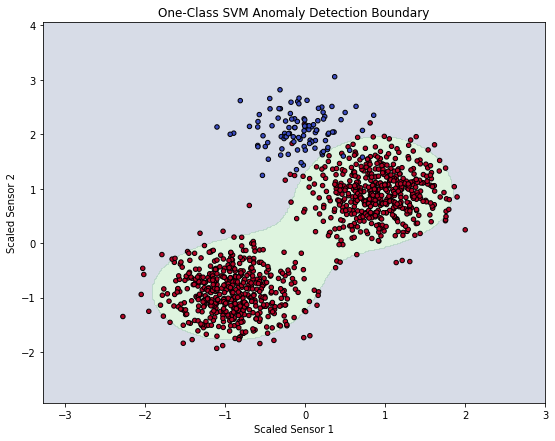

In [117]:
# Visualize the learned decision boundary
x_min, x_max = X_all_scaled[:, 0].min() - 1, X_all_scaled[:, 0].max() + 1
y_min, y_max = X_all_scaled[:, 1].min() - 1, X_all_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

Z = model.predict(grid)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(9, 7))

plt.contourf(
    xx, yy, Z,
    levels=[-1, 0, 1],
    alpha=0.2
)

plt.scatter(
    X_all_scaled[:, 0],
    X_all_scaled[:, 1],
    c=y_true,
    cmap="coolwarm",
    edgecolors="k",
    s=20
)

plt.title("One-Class SVM Anomaly Detection Boundary")
plt.xlabel("Scaled Sensor 1")
plt.ylabel("Scaled Sensor 2")
plt.show()

In [118]:
# Investigate contamination assumptions
contamination_results = []

for nu in [0.01, 0.03, 0.05, 0.10, 0.15, 0.20]:

    svm = OneClassSVM(
        kernel="rbf",
        nu=nu,
        gamma="scale"
    )

    svm.fit(X_safe_scaled)

    predictions = svm.predict(X_all_scaled)

    contamination_results.append({
        "nu": nu,
        "Predicted Anomalies": np.sum(predictions == -1),
        "Predicted Anomaly Percentage": np.mean(predictions == -1) * 100
    })

contamination_df = pd.DataFrame(contamination_results)

display(contamination_df)

,nu,Predicted Anomalies,Predicted Anomaly Percentage
0,0.01,79,7.181818
1,0.03,121,11.000000
2,0.05,146,13.272727
3,0.10,198,18.000000
4,0.15,250,22.727273
5,0.20,298,27.090909


In [ ]:
Problem 11: Support Vector Regression

In [119]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVR
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

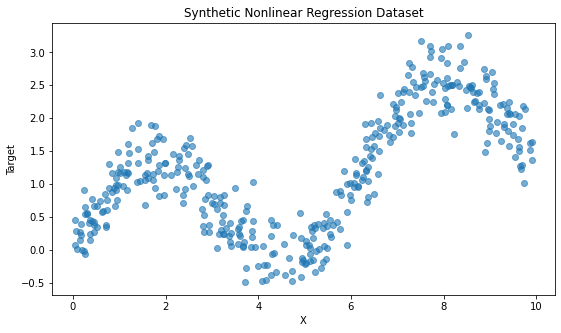

In [120]:
# Generate synthetic regression data
np.random.seed(42)

X = np.sort(10 * np.random.rand(400, 1), axis=0)

noise = np.random.normal(0, 0.3, size=400)

y = (
    np.sin(X.ravel())
    + 0.2 * X.ravel()
    + noise
)

plt.figure(figsize=(9, 5))
plt.scatter(X, y, alpha=0.6)

plt.xlabel("X")
plt.ylabel("Target")
plt.title("Synthetic Nonlinear Regression Dataset")
plt.show()

In [121]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 300
Testing samples: 100


In [122]:
# Train an SVR model
model = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(
        kernel="rbf",
        C=1.0,
        epsilon=0.1,
        gamma="scale"
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("MAE:", mae)
print("RMSE:", rmse)

print(
    "Support vectors:",
    len(model.named_steps["svr"].support_)
)

MAE: 0.2116377472468275
RMSE: 0.26056098366543895
Support vectors: 221


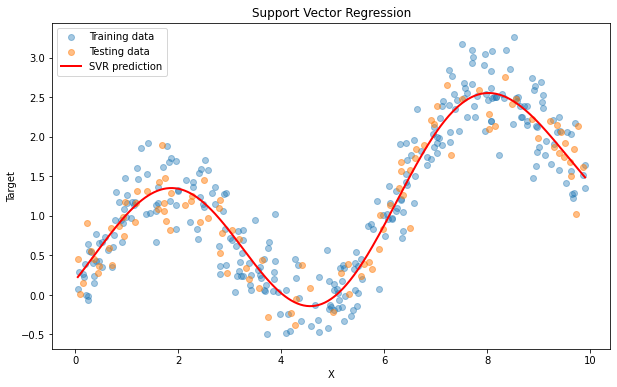

In [123]:
# Visualize predictions
X_plot = np.linspace(
    X.min(),
    X.max(),
    500
).reshape(-1, 1)

y_plot = model.predict(X_plot)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_train, y_train,
    label="Training data",
    alpha=0.4
)

plt.scatter(
    X_test, y_test,
    label="Testing data",
    alpha=0.5
)

plt.plot(
    X_plot, y_plot,
    color="red",
    linewidth=2,
    label="SVR prediction"
)

plt.xlabel("X")
plt.ylabel("Target")
plt.title("Support Vector Regression")
plt.legend()
plt.show()

In [124]:
# Investigate the effect of epsilon
epsilon_values = [0.01, 0.05, 0.1, 0.2, 0.5, 1.0]

epsilon_results = []

for eps in epsilon_values:

    svr_model = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(
            kernel="rbf",
            C=1.0,
            epsilon=eps
        ))
    ])

    svr_model.fit(X_train, y_train)

    predictions = svr_model.predict(X_test)

    svr = svr_model.named_steps["svr"]

    epsilon_results.append({
        "Epsilon": eps,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "Support Vectors": len(svr.support_)
    })

epsilon_df = pd.DataFrame(epsilon_results)

display(epsilon_df)

,Epsilon,MAE,RMSE,Support Vectors
0,0.01,0.210044,0.257941,293
1,0.05,0.210553,0.259659,265
2,0.10,0.211638,0.260561,221
3,0.20,0.210129,0.259539,158
4,0.50,0.216890,0.267779,40
5,1.00,0.350772,0.426113,8


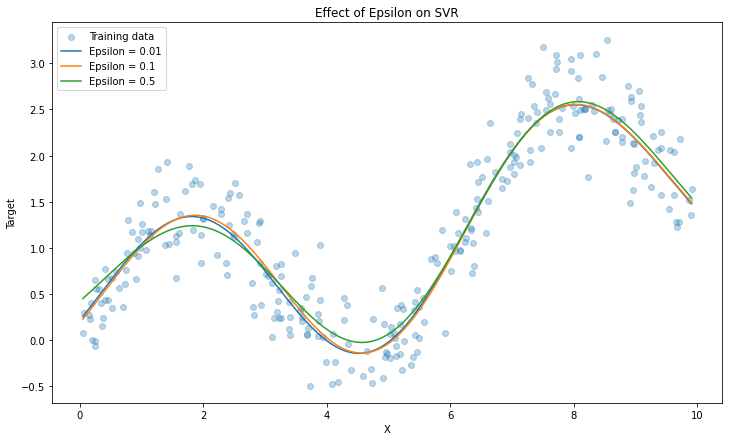

In [125]:
# Visualize different epsilon values
plt.figure(figsize=(12, 7))

plt.scatter(
    X_train, y_train,
    alpha=0.3,
    label="Training data"
)

for eps in [0.01, 0.1, 0.5]:

    svr_model = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(
            kernel="rbf",
            C=1.0,
            epsilon=eps
        ))
    ])

    svr_model.fit(X_train, y_train)

    predictions = svr_model.predict(X_plot)

    plt.plot(
        X_plot,
        predictions,
        label=f"Epsilon = {eps}"
    )

plt.xlabel("X")
plt.ylabel("Target")
plt.title("Effect of Epsilon on SVR")
plt.legend()
plt.show()

In [126]:
# Investigate the effect of C
C_values = [0.01, 0.1, 1, 10, 100]

C_results = []

for c in C_values:

    svr_model = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(
            kernel="rbf",
            C=c,
            epsilon=0.1
        ))
    ])

    svr_model.fit(X_train, y_train)

    predictions = svr_model.predict(X_test)

    svr = svr_model.named_steps["svr"]

    C_results.append({
        "C": c,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "Support Vectors": len(svr.support_)
    })

C_df = pd.DataFrame(C_results)

display(C_df)

,C,MAE,RMSE,Support Vectors
0,0.01,0.437410,0.531250,278
1,0.10,0.248610,0.303147,235
2,1.00,0.211638,0.260561,221
3,10.00,0.213431,0.267039,220
4,100.00,0.212919,0.266460,225


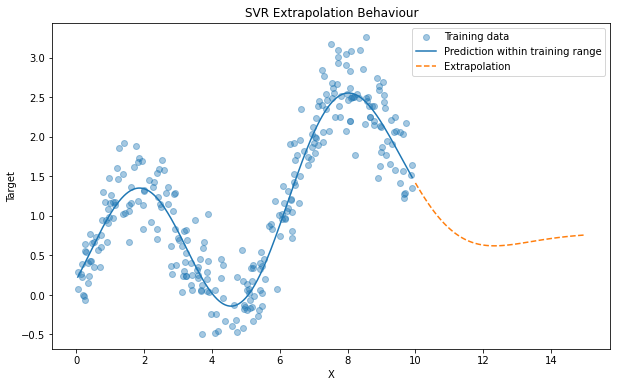

In [127]:
# Investigate extrapolation
X_extrapolation = np.linspace(
    10,
    15,
    100
).reshape(-1, 1)

y_extrapolation = model.predict(X_extrapolation)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_train,
    y_train,
    alpha=0.4,
    label="Training data"
)

plt.plot(
    X_plot,
    model.predict(X_plot),
    label="Prediction within training range"
)

plt.plot(
    X_extrapolation,
    y_extrapolation,
    linestyle="--",
    label="Extrapolation"
)

plt.xlabel("X")
plt.ylabel("Target")
plt.title("SVR Extrapolation Behaviour")
plt.legend()
plt.show()

In [128]:
# Compare different SVR configurations
configurations = [
    {"C": 0.1, "epsilon": 0.1},
    {"C": 1, "epsilon": 0.1},
    {"C": 10, "epsilon": 0.1},
    {"C": 1, "epsilon": 0.01},
    {"C": 1, "epsilon": 0.5}
]

comparison = []

for config in configurations:

    svr_model = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(
            kernel="rbf",
            C=config["C"],
            epsilon=config["epsilon"]
        ))
    ])

    svr_model.fit(X_train, y_train)

    predictions = svr_model.predict(X_test)

    svr = svr_model.named_steps["svr"]

    comparison.append({
        "C": config["C"],
        "Epsilon": config["epsilon"],
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "Support Vectors": len(svr.support_)
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.sort_values("RMSE"))

,C,Epsilon,MAE,RMSE,Support Vectors
3,1.0,0.01,0.210044,0.257941,293
1,1.0,0.10,0.211638,0.260561,221
2,10.0,0.10,0.213431,0.267039,220
4,1.0,0.50,0.216890,0.267779,40
0,0.1,0.10,0.248610,0.303147,235


In [ ]:
Problem 12: Performance vs Deployment Cost

In [129]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import pickle
import os

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.kernel_approximation import RBFSampler, Nystroem
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    average_precision_score,
    classification_report
)

Dataset shape: (5000, 2)
Classes: [0 1]


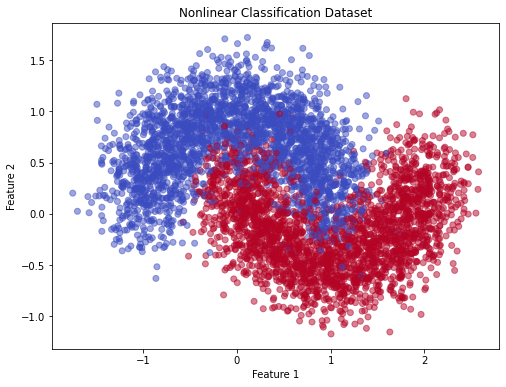

In [130]:
# Generate dataset
X, y = make_moons(
    n_samples=5000,
    noise=0.25,
    random_state=42
)

print("Dataset shape:", X.shape)
print("Classes:", np.unique(y))

plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    alpha=0.5
)

plt.title("Nonlinear Classification Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [131]:
# Split and scale the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 3750
Testing samples: 1250


In [132]:
# Train Linear SVM
linear_model = LinearSVC(
    C=1.0,
    max_iter=10000,
    random_state=42
)

start = time.perf_counter()

linear_model.fit(
    X_train_scaled,
    y_train
)

linear_train_time = time.perf_counter() - start

start = time.perf_counter()

linear_predictions = linear_model.predict(X_test_scaled)

linear_predict_time = time.perf_counter() - start

In [133]:
# Train Exact RBF SVM
rbf_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

start = time.perf_counter()

rbf_model.fit(
    X_train_scaled,
    y_train
)

rbf_train_time = time.perf_counter() - start

start = time.perf_counter()

rbf_predictions = rbf_model.predict(X_test_scaled)

rbf_predict_time = time.perf_counter() - start

In [134]:
# Train Approximate RBF SVM using RBFSampler
approx_rbf_model = Pipeline([
    (
        "rbf_features",
        RBFSampler(
            gamma=1.0,
            n_components=500,
            random_state=42
        )
    ),
    (
        "svm",
        LinearSVC(
            C=1.0,
            max_iter=10000,
            random_state=42
        )
    )
])

start = time.perf_counter()

approx_rbf_model.fit(
    X_train_scaled,
    y_train
)

approx_train_time = time.perf_counter() - start

start = time.perf_counter()

approx_predictions = approx_rbf_model.predict(X_test_scaled)

approx_predict_time = time.perf_counter() - start

In [135]:
# Evaluate all three models
models = {
    "Linear SVM": (linear_model, linear_predictions),
    "Exact RBF SVM": (rbf_model, rbf_predictions),
    "Approximate RBF SVM": (approx_rbf_model, approx_predictions)
}

results = []

for name, (model, predictions) in models.items():

    if name == "Linear SVM":
        scores = model.decision_function(X_test_scaled)

    elif name == "Exact RBF SVM":
        scores = model.decision_function(X_test_scaled)

    else:
        scores = model.decision_function(X_test_scaled)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "Average Precision": average_precision_score(y_test, scores)
    })

results_df = pd.DataFrame(results)

display(results_df)

,Model,Accuracy,F1 Score,Average Precision
0,Linear SVM,0.8712,0.871917,0.948195
1,Exact RBF SVM,0.9472,0.947452,0.987632
2,Approximate RBF SVM,0.9456,0.945860,0.987643


In [136]:
# Compare training and prediction time
timing_df = pd.DataFrame([
    {
        "Model": "Linear SVM",
        "Training Time (seconds)": linear_train_time,
        "Prediction Time (seconds)": linear_predict_time
    },
    {
        "Model": "Exact RBF SVM",
        "Training Time (seconds)": rbf_train_time,
        "Prediction Time (seconds)": rbf_predict_time
    },
    {
        "Model": "Approximate RBF SVM",
        "Training Time (seconds)": approx_train_time,
        "Prediction Time (seconds)": approx_predict_time
    }
])

display(timing_df)

,Model,Training Time (seconds),Prediction Time (seconds)
0,Linear SVM,0.014383,0.000384
1,Exact RBF SVM,0.098327,0.056030
2,Approximate RBF SVM,0.305799,0.014255


In [137]:
# Compare model storage size
model_objects = {
    "Linear SVM": linear_model,
    "Exact RBF SVM": rbf_model,
    "Approximate RBF SVM": approx_rbf_model
}

storage_results = []

for name, model in model_objects.items():

    filename = name.replace(" ", "_") + ".pkl"

    with open(filename, "wb") as file:
        pickle.dump(model, file)

    size_kb = os.path.getsize(filename) / 1024

    storage_results.append({
        "Model": name,
        "Storage Size (KB)": size_kb
    })

storage_df = pd.DataFrame(storage_results)

display(storage_df)

,Model,Storage Size (KB)
0,Linear SVM,0.601562
1,Exact RBF SVM,24.930664
2,Approximate RBF SVM,16.565430


In [138]:
# Investigate feature map size
component_values = [50, 100, 250, 500, 1000]

feature_results = []

for components in component_values:

    sampler = RBFSampler(
        gamma=1.0,
        n_components=components,
        random_state=42
    )

    X_transformed = sampler.fit_transform(X_train_scaled)

    feature_results.append({
        "Components": components,
        "Transformed Shape": str(X_transformed.shape),
        "Feature Matrix Size (MB)": (
            X_transformed.nbytes / (1024 ** 2)
        )
    })

feature_df = pd.DataFrame(feature_results)

display(feature_df)

,Components,Transformed Shape,Feature Matrix Size (MB)
0,50,"(3750, 50)",1.430511
1,100,"(3750, 100)",2.861023
2,250,"(3750, 250)",7.152557
3,500,"(3750, 500)",14.305115
4,1000,"(3750, 1000)",28.610229


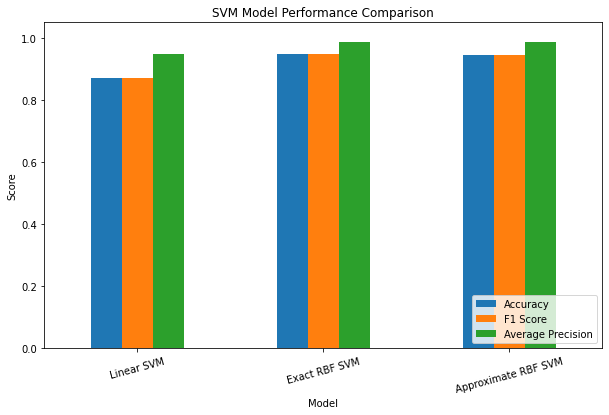

In [139]:
# Visualize performance comparison
metrics = ["Accuracy", "F1 Score", "Average Precision"]

results_plot = results_df.set_index("Model")

results_plot[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("SVM Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.show()

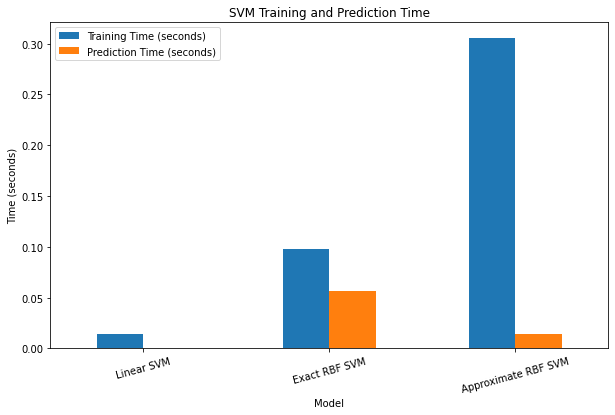

In [140]:
# Compare inference time
timing_plot = timing_df.set_index("Model")

timing_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("SVM Training and Prediction Time")
plt.ylabel("Time (seconds)")
plt.xticks(rotation=15)
plt.show()